# Exercice 4 : Inférence d'appartenance, « ce patient était-il dans les données d'entraînement ? »

> **Objectif.** Attaquer un modèle médical publié : deviner, à partir de ses seules prédictions, quels patients ont servi à l'entraîner.
> Comparer un modèle **sur-appris** et un modèle **régularisé**, et relier la fuite à l'écart entre précision d'entraînement et de test.

**Volets du plan de cours (séance 12) :** *prévention des fuites d'information* : la fuite ne passe plus par les données publiées, mais par le **modèle** publié.

**Le scénario.** Un hôpital entraîne un modèle de risque de **prédiabète** sur les dossiers de 1 000 de ses patients et le met à disposition (API qui renvoie une probabilité).
Un attaquant (assureur, employeur, ex-conjoint) a le dossier d'une personne et veut savoir si elle est **patiente de cet hôpital**. Si l'hôpital est une clinique spécialisée (dépendances, VIH, oncologie), la simple appartenance est un renseignement de santé.

**Dépendances :** `torch`, `scikit-learn`, `matplotlib` (installés par l'étape 0).

**Les données.** Les 10 262 patients adultes du jeu **Synthea « 10K COVID-19 »** (Apache 2.0, patients synthétiques), déjà utilisés à l'exercice 3 : âge, sexe, origine, dépenses de santé et 60 diagnostics présents/absents. Cible : prédiabète (38 % des adultes).

**Le plan.**
1. Préparer les données : membres, non-membres, test.
2. Entraîner un modèle sur-appris.
3. Regarder les pertes des membres et des non-membres.
4. L'attaque par seuil.
5. Même chose avec un modèle régularisé.

## Étape 0 : exécutez cette cellule en premier
Elle installe les paquets manquants et, sur Colab, récupère `helper.py` et `data/` depuis GitHub. Elle doit afficher **Prêt : True**.

In [1]:
# Dépendances de ce notebook : torch scikit-learn matplotlib
import os, sys, importlib.util
if not os.path.exists('helper.py'):   # notebook ouvert depuis Google Drive / Colab
    !test -d /content/cours || git clone -q --depth 1 https://github.com/elyesmanai/8IAR805---Cybersecurity-AI.git /content/cours
    %cd "/content/cours/Chapitre 7 - IA et vie privée"
manquants = [pip for module, pip in {'torch': 'torch', 'sklearn': 'scikit-learn', 'matplotlib': 'matplotlib'}.items() if importlib.util.find_spec(module) is None]
if manquants:
    %pip install -q {' '.join(manquants)}
print('Prêt :', os.path.exists('helper.py') and os.path.exists('data'))

Prêt : True


## Étape 1 : Membres, non-membres, test
**Ce qu'on fait :** 1 000 patients servent à l'entraînement (les **membres**). 1 000 autres, jamais vus, servent de **non-membres** pour évaluer l'attaque. Le reste mesure la précision du modèle.

In [2]:
from helper import dossiers_medicaux, decoupage
X, y, colonnes = dossiers_medicaux()
membres, non_membres, test = decoupage(len(X), n_train=1000)
print(X.shape, f'prédiabète : {y.mean():.0%}')

(10262, 68) prédiabète : 38%


## Étape 2 : Un modèle sur-appris
**Ce qu'on fait :** un réseau à deux couches cachées de 256 neurones, 150 époques, aucune régularisation. C'est ce qui arrive quand on entraîne « jusqu'à ce que la perte d'entraînement soit nulle ».

In [3]:
from helper import creer_mlp, entrainer, precision_test
import torch; torch.set_num_threads(4)

surappris = entrainer(creer_mlp(X.shape[1]), X[membres], y[membres], epoques=150)
print(f'Précision entraînement : {precision_test(surappris, X[membres], y[membres]):.3f}')
print(f'Précision test         : {precision_test(surappris, X[test], y[test]):.3f}')

Précision entraînement : 0.999
Précision test         : 0.855


**👀 Ce qu'on doit voir :** ≈ 100 % sur l'entraînement, ≈ 86 % en test. Le modèle a **mémorisé** ses 1 000 patients.

## Étape 3 : Les pertes trahissent les membres
**Ce qu'on fait :** pour chaque patient, la **perte** = à quel point le modèle se trompe sur lui. L'attaquant peut la calculer : il a le dossier (donc la vraie étiquette) et l'API lui donne la probabilité.

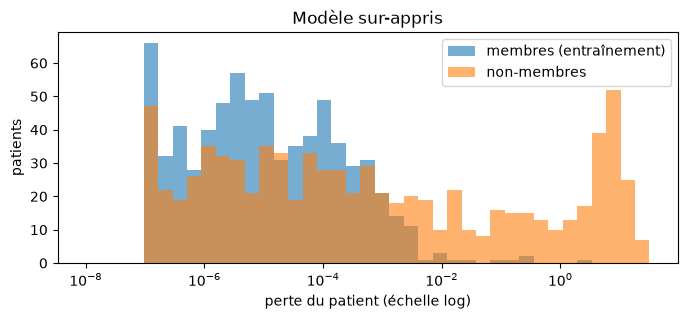

In [4]:
import numpy as np, matplotlib.pyplot as plt
from helper import pertes

def histogramme(modele, titre):
    bins = np.logspace(-8, 1.5, 40)
    plt.figure(figsize=(8, 3))
    plt.hist(pertes(modele, X[membres], y[membres]) + 1e-8, bins=bins, alpha=0.6, label='membres (entraînement)')
    plt.hist(pertes(modele, X[non_membres], y[non_membres]) + 1e-8, bins=bins, alpha=0.6, label='non-membres')
    plt.xscale('log'); plt.xlabel('perte du patient (échelle log)'); plt.ylabel('patients'); plt.title(titre); plt.legend()

histogramme(surappris, 'Modèle sur-appris')

**👀 Ce qu'on doit voir :** **tous** les membres ont une perte quasi nulle (moins de 0,01) : le modèle les « reconnaît ». Les non-membres se répartissent en deux groupes : ceux que le modèle classe bien (perte faible, comme les membres) et ceux qu'il rate (bosse à droite, perte proche de 1). Un patient dans cette bosse n'a presque certainement **pas** servi à l'entraînement.

## Étape 4 : L'attaque par seuil
**L'idée (Yeom *et al.*, CSF 2018) :** « si la perte est plus petite qu'un seuil, je parie que le patient était dans l'entraînement ». Pas besoin de modèles fantômes (*shadow models*) comme chez Shokri *et al.* (2017) : la version la plus simple suffit à montrer la fuite.
On mesure l'attaque par son **AUC** (0,5 = pile ou face) et son **avantage** (vrais positifs − faux positifs, au meilleur seuil).

In [5]:
seuil = pertes(surappris, X[membres], y[membres]).mean()     # l'attaquant connaît la perte moyenne d'entraînement (souvent publiée)
devine_membre = lambda idx: pertes(surappris, X[idx], y[idx]) < seuil
print(f"Membres reconnus comme membres        : {devine_membre(membres).mean():.0%}")
print(f"Non-membres pris à tort pour membres : {devine_membre(non_membres).mean():.0%}")

Membres reconnus comme membres        : 99%
Non-membres pris à tort pour membres : 71%


In [6]:
from helper import attaque_appartenance
resultats = {'sur-appris': {'précision test': precision_test(surappris, X[test], y[test]),
                            **attaque_appartenance(surappris, X, y, membres, non_membres)}}
resultats

{'sur-appris': {'précision test': 0.855119825708061,
  'AUC': 0.66,
  'avantage': 0.298}}

**👀 Ce qu'on doit voir :** avec ce seuil naïf, ≈ 98 % des membres sont reconnus, mais ≈ 71 % des non-membres aussi : l'attaque n'est pas sûre d'elle patient par patient. Mesurée sur tous les seuils, elle a une AUC ≈ 0,66 et un **avantage** d'environ 30 points sur le hasard. Sur un hôpital réel, ces points d'avantage, ce sont des patients dont on révèle la fréquentation.

## Étape 5 : Un modèle régularisé
**Ce qu'on fait :** même réseau, mais avec les remèdes classiques contre le sur-apprentissage : *weight decay*, *dropout* 30 %, et 20 époques au lieu de 150.

Précision entraînement : 0.908
Précision test         : 0.880


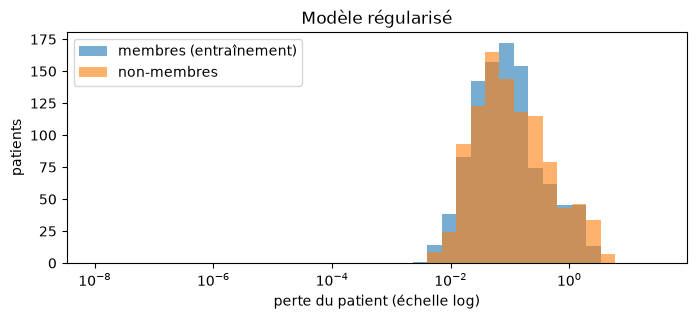

In [7]:
regularise = entrainer(creer_mlp(X.shape[1], dropout=0.3), X[membres], y[membres], epoques=20, weight_decay=1e-2)
print(f'Précision entraînement : {precision_test(regularise, X[membres], y[membres]):.3f}')
print(f'Précision test         : {precision_test(regularise, X[test], y[test]):.3f}')
histogramme(regularise, 'Modèle régularisé')

In [8]:
import pandas as pd
resultats['régularisé'] = {'précision test': precision_test(regularise, X[test], y[test]),
                           **attaque_appartenance(regularise, X, y, membres, non_membres)}
for nom, m in [('sur-appris', surappris), ('régularisé', regularise)]:
    resultats[nom]['écart entraînement - test'] = precision_test(m, X[membres], y[membres]) - precision_test(m, X[test], y[test])
pd.DataFrame(resultats).T.round(3)

,précision test,AUC,avantage,écart entraînement - test
sur-appris,0.855,0.660,0.298,0.144
régularisé,0.880,0.535,0.087,0.028


**👀 Ce qu'on doit voir :** le modèle régularisé est **meilleur** en test (≈ 0,88 contre 0,86) **et** l'attaque tombe presque à pile ou face (AUC ≈ 0,54, avantage ≈ 9 points). L'écart entraînement-test suit l'AUC de l'attaque : c'est le résultat central de Yeom *et al.* (le sur-apprentissage suffit à créer la fuite).

**❓ Question pour la classe :** le modèle régularisé est-il « sûr » ? On a mesuré **une** attaque, en moyenne. Rien ne garantit qu'un patient atypique (un cas rare, très mémorisé) ne soit pas reconnaissable, ni qu'une attaque plus forte (modèles fantômes, LiRA) échoue aussi.

## Ce qu'il faut retenir
- Un modèle publié peut révéler **qui** était dans ses données d'entraînement. En santé, l'appartenance elle-même est sensible.
- L'attaque la plus simple compare la **perte** d'un patient à un seuil : elle exploite directement le **sur-apprentissage**.
- La régularisation réduit beaucoup la fuite (et améliore souvent le modèle), mais ne donne **aucune garantie**.
- Pour une garantie mathématique, il faut la **confidentialité différentielle** : c'est l'exercice suivant.

**Exercice suivant :** DP-SGD avec Opacus, et la courbe précision vs ε.